# 02. 분할·잘림·시간 추이 분석

01 출력으로 다음을 본다. 분할은 **아래 설정 셀의 변수만 바꿔** 다시 돌리면 된다.

1. 구간(train/val/test)별 클래스 엣지 수·비율, 패턴별 시도 수
2. 구간 경계에서 잘리는 시도 — 한 시도가 둘 이상 구간에 걸치는 것 (패턴별)
3. `DATA_END` 이후를 뺄 때 끝이 잘리는 시도 (패턴별), 클래스별 마지막 거래일
4. 클래스별 일별 추이, 패턴별 시도 시작·길이
5. 여러 분할 후보 비교

**잘림이 왜 중요한가** (입력 = 의심 거래만 모은 그래프, 구간 끝까지 누적)
- 학습 엣지의 시도가 검증·테스트로 이어지면 → 학습 그래프에서는 그 시도의 뒷부분이 안 보인다 (잘린 맥락으로 학습)
- 테스트 엣지의 시도가 학습 구간에서 시작했으면 → 같은 시도의 앞부분을 학습에서 봤다 (누수 후보)
- 둘 다 막을 수는 없고, 얼마나 되는지 알아야 지표를 해석할 수 있다

## 0. 설정

In [1]:
import sys
from pathlib import Path
import pandas as pd
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)

sys.path.append(str(Path.cwd()))
import mc_lib as M

DATASET = "HI-Large"

# 분할 — 양끝 날짜 포함. 기본값은 이진 실험과 같음 (M.WINDOWS)
TRAIN = ("2022-08-08", "2022-10-02")
VAL   = ("2022-10-03", "2022-10-16")
TEST  = ("2022-10-17", "2022-10-30")

DATA_END   = "2022-10-31"     # 이 날짜까지만 쓴다 (11월 이후 제외)
NORMAL_END = "2022-11-05"     # 정상 거래 마지막 날 (01 summary 의 last_day_normal 로 확인)

windows = M.make_windows(TRAIN, VAL, TEST)
OUT = M.results_dir(DATASET, "02_split_analysis")
windows

{'train': (Timestamp('2022-08-08 00:00:00'), Timestamp('2022-10-03 00:00:00')),
 'val': (Timestamp('2022-10-03 00:00:00'), Timestamp('2022-10-17 00:00:00')),
 'test': (Timestamp('2022-10-17 00:00:00'), Timestamp('2022-10-31 00:00:00'))}

In [3]:
lau = M.load_laundering(DATASET)          # 세탁 거래 (엣지 단위, 라벨)
att = M.load_attempts(DATASET)            # 시도 단위
members = M.load_members(DATASET)         # 패턴 파일 행 (시도 × 거래)
daily = M.load_daily(DATASET)             # 일별 전체·세탁·정상 거래 수
print(f"세탁 엣지 {len(lau):,}  시도 {len(att):,}  패턴 행 {len(members):,}")
print("정상 거래 마지막 날:", daily.index[daily['n_normal'] > 0].max().date(), " / 세탁 마지막 날:", lau['ts'].max())

세탁 엣지 225,546  시도 16,467  패턴 행 137,936
정상 거래 마지막 날: 2023-01-12  / 세탁 마지막 날: 2023-01-12 16:49:00


## 1. 구간별 클래스 수

- `edges` : 클래스 × 구간 엣지 수 (라벨 기준 1거래 1행). before = 학습 시작 전, after = 테스트 끝 뒤(11월 꼬리 포함)
- `edges_share` : 각 구간 안에서 클래스 비율(%) — 구간마다 분포가 크게 다르면 검증·테스트 지표 해석에 주의
- `attempts_start` : 시도가 **시작한** 구간 기준 시도 수
- `attempts_touch` : 그 구간에 거래가 1건이라도 있는 시도 수 (한 시도가 여러 열에 셈)

In [4]:
sc = M.split_counts(lau, members, att, windows)
sc["edges"]

period,before,train,val,test,gap,after,total
pattern_type,,,,,,,
FAN-OUT,281,6045,1980,2131,0,3117,13554
FAN-IN,215,6465,1897,1922,0,2788,13287
GATHER-SCATTER,291,9012,3845,3785,0,9428,26361
SCATTER-GATHER,285,12537,3909,3891,0,6356,26978
CYCLE,229,6025,1765,1853,0,2468,12340
RANDOM,159,4948,1425,1335,0,1751,9618
BIPARTITE,180,6437,1730,1833,0,1994,12174
STACK,155,11420,3549,3437,0,5063,23624
UNMATCHED,5411,47782,13695,14273,0,6449,87610


In [5]:
sc["edges_share"]

period,train,val,test
pattern_type,,,
FAN-OUT,5.46,5.86,6.18
FAN-IN,5.84,5.61,5.58
GATHER-SCATTER,8.14,11.38,10.98
SCATTER-GATHER,11.33,11.57,11.29
CYCLE,5.44,5.22,5.38
RANDOM,4.47,4.22,3.87
BIPARTITE,5.82,5.12,5.32
STACK,10.32,10.50,9.97
UNMATCHED,43.17,40.52,41.42


In [6]:
sc["attempts_start"]

period,before,train,val,test,gap,after,total
pattern_type,,,,,,,
FAN-OUT,169,1120,326,291,0,134,2040
FAN-IN,147,1160,288,285,0,134,2014
GATHER-SCATTER,163,1186,303,277,0,125,2054
SCATTER-GATHER,135,1189,304,297,0,142,2067
CYCLE,150,1241,310,277,0,108,2086
RANDOM,115,1179,306,278,0,123,2001
BIPARTITE,76,1184,288,325,0,236,2109
STACK,67,1172,303,324,0,230,2096
ALL,1022,9431,2428,2354,0,1232,16467


In [7]:
sc["attempts_touch"]

period,before,train,val,test,gap,after
pattern_type,,,,,,
FAN-OUT,169,1260,741,756,0,638
FAN-IN,147,1275,725,730,0,569
GATHER-SCATTER,163,1316,1149,1133,0,1086
SCATTER-GATHER,135,1324,890,860,0,758
CYCLE,150,1384,794,789,0,634
RANDOM,115,1258,637,618,0,458
BIPARTITE,76,1252,456,497,0,430
STACK,67,1239,816,831,0,769


## 2. 구간 경계에서 잘리는 시도

- `cut` : 둘 이상 구간에 걸친 시도. `before|train` … `test|after` : 그 두 구간 모두에 거래가 있는 시도 수
- `outside_share_med(cut)` : 걸친 시도에서 첫 구간 밖으로 나간 행 비율의 중앙값 (클수록 크게 잘림)
- `edge_exposure` : 구간별 패턴 엣지 중 같은 시도가 앞 구간에도 있는 비율(`with_earlier_%`), 뒤 구간에도 있는 비율(`with_later_%`)
  - train 의 `with_earlier_%` 는 before 구간 거래가 학습 그래프의 맥락으로 들어가므로 문제 아님
  - **test 의 `with_earlier_%` = 누수 후보**, **train 의 `with_later_%` = 잘린 맥락으로 학습하는 비율**

In [8]:
bc = M.boundary_cuts(members, windows)
bc["by_pattern"]

,attempts,cut,cut_%,before|train,train|val,val|test,test|after,outside_share_med(cut)
pattern_type,,,,,,,,
FAN-OUT,2040,1070,52.45,140,415,439,465,0.636
FAN-IN,2014,1024,50.84,115,437,411,395,0.625
GATHER-SCATTER,2054,1444,70.30,130,846,790,885,0.750
SCATTER-GATHER,2067,1331,64.39,135,586,534,579,0.625
CYCLE,2086,1239,59.40,143,484,448,482,0.545
RANDOM,2001,814,40.68,79,331,318,322,0.600
BIPARTITE,2109,581,27.55,68,168,172,194,0.600
STACK,2096,1158,55.25,67,513,485,513,0.500
ALL,16467,8661,52.60,877,3780,3597,3835,0.607


In [9]:
bc["edge_exposure"].unstack(0)

n             with_earlier_%               with_later_%              
period          train   val  test          train    val   test        train    val   test
pattern_type                                                                             
FAN-OUT          6045  1980  2131          15.17  66.16  69.64        31.33  72.12  69.45
FAN-IN           6465  1897  1922          11.91  69.69  68.83        31.25  68.85  60.77
GATHER-SCATTER   9012  3845  3785          19.62  80.75  82.75        78.65  82.26  85.18
SCATTER-GATHER  12537  3909  3891          12.74  71.63  76.00        35.61  74.16  75.28
CYCLE            6025  1765  1853           9.83  64.87  69.13        29.41  65.67  66.86
RANDOM           4948  1425  1335           8.31  59.44  62.40        25.55  61.19  62.55
BIPARTITE        6437  1730  1833           7.18  46.94  43.64        10.69  43.47  46.15
STACK           11420  3549  3437           6.52  64.92  63.02        41.44  80.59  79.43

## 2-1. 라벨 겹침(누수 후보)과 성숙도

2절 `with_earlier_%` 는 검증 구간 맥락까지 섞인 값이라, **같은 시도의 엣지가 학습 라벨로 쓰였는지**를 따로 본다.
- `new_%` : 시도가 그 분할에서 시작 → 앞 구간에 흔적 없는 **깨끗한 평가 묶음**
- `in_train_%` : 같은 시도가 학습 구간에도 엣지가 있음 → val·test 에서는 **라벨 누수 후보** (학습 때 같은 시도의 다른 엣지 정답을 봄)
- `in_val_%` : 같은 시도가 검증 구간에도 있음 (test 에서 = 모델 선택에 쓰인 시도)
- `before_%` : 시도가 학습 시작 전에 시작 — 앞부분은 라벨 없이 맥락으로만 보임

`attempts` : 분할별 시도 수. `touch` = 그 분할에 엣지가 있는 시도, `also_train` = 그중 학습에도 있는 시도, `new` = 그 분할에서 시작

In [ ]:
lo = M.label_overlap(members, att, windows)
lo["edges"]

In [ ]:
lo["attempts"]

성숙도 = 엣지 시각 − 시도 시작 (일). 분할마다 패턴 엣지가 시도의 어느 단계에 몰려 있는지 — 학습이 램프업 구간(8월)이라 초반 엣지가 많은지 확인

In [ ]:
age = M.edge_age(lau, att, windows)
age["quantiles"].unstack(0)

In [ ]:
age["bins"]

## 3. `DATA_END` 이후를 뺄 때

- `complete` : DATA_END 안에서 끝난 시도 / `truncated` : 안에서 시작해 밖으로 이어진 시도 / `started_after` : 밖에서 시작한 시도
- `rows_after` : 잘려 나가는 패턴 행 수, `lost_share_*` : 잘린 시도가 잃는 행 비율
- `edges` : 클래스별 DATA_END 까지 / 이후 엣지 수 — **UNMATCHED 의 after_end 가 0 인지** 확인
- `last_seen` : 클래스별 첫·마지막 거래 시각

In [10]:
tr = M.truncation(members, att, lau, DATA_END)
tr["attempts"]

,attempts,complete,truncated,started_after,truncated_%,rows_after,lost_share_med(trunc),lost_share_max(trunc)
pattern_type,,,,,,,,
FAN-OUT,2040,1422,514,104,25.20,2956,0.500,0.938
FAN-IN,2014,1470,438,106,21.75,2646,0.500,0.929
GATHER-SCATTER,2054,989,962,103,46.84,9152,0.500,0.968
SCATTER-GATHER,2067,1332,618,117,29.90,6085,0.500,0.969
CYCLE,2086,1479,519,88,24.88,2330,0.500,0.923
RANDOM,2001,1563,331,107,16.54,1669,0.500,0.917
BIPARTITE,2109,1701,191,217,9.06,1862,0.533,0.929
STACK,2096,1353,534,209,25.48,4821,0.500,0.964
ALL,16467,11309,4107,1051,24.94,31521,0.500,0.969


In [11]:
tr["edges"]

,until_end,after_end,after_%
pattern_type,,,
FAN-OUT,10598,2956,21.81
FAN-IN,10641,2646,19.91
GATHER-SCATTER,17209,9152,34.72
SCATTER-GATHER,20893,6085,22.56
CYCLE,10010,2330,18.88
RANDOM,7949,1669,17.35
BIPARTITE,10312,1862,15.29
STACK,18803,4821,20.41
UNMATCHED,82260,5350,6.11


In [12]:
tr["last_seen"]

,min,max
pattern_type,,
FAN-OUT,2022-08-01 00:36:00,2022-12-10 15:28:00
FAN-IN,2022-08-01 00:08:00,2022-12-10 00:40:00
GATHER-SCATTER,2022-08-01 00:10:00,2023-01-12 16:49:00
SCATTER-GATHER,2022-08-01 02:10:00,2022-12-10 18:19:00
CYCLE,2022-08-01 00:08:00,2022-12-10 09:26:00
RANDOM,2022-08-01 03:47:00,2022-12-07 17:36:00
BIPARTITE,2022-08-01 06:11:00,2022-11-22 07:52:00
STACK,2022-08-01 11:08:00,2022-12-17 18:04:00
UNMATCHED,2022-08-01 00:01:00,2022-11-05 23:59:00


In [13]:
# 정상 거래가 끝나는 날(NORMAL_END) 기준으로도 — 그 뒤에 새로 시작하는 시도가 있나 (started_after)
tr_n = M.truncation(members, att, lau, NORMAL_END)
tr_n["attempts"][["attempts", "complete", "truncated", "started_after", "truncated_%", "rows_after"]]

,attempts,complete,truncated,started_after,truncated_%,rows_after
pattern_type,,,,,,
FAN-OUT,2040,1554,486,0,23.82,2171
FAN-IN,2014,1582,431,1,21.40,1963
GATHER-SCATTER,2054,1101,953,0,46.40,7726
SCATTER-GATHER,2067,1436,631,0,30.53,4654
CYCLE,2086,1574,512,0,24.54,1788
RANDOM,2001,1659,342,0,17.09,1162
BIPARTITE,2109,1809,194,106,9.20,1200
STACK,2096,1462,537,97,25.62,3609
ALL,16467,12177,4086,204,24.81,24273


In [14]:
# 패턴별 시도 길이(일)·크기(행 수) — 길수록 경계에 잘리기 쉽다
M.duration_table(att)

,duration_d_p50,duration_d_p90,duration_d_p99,duration_d_max,n_rows_p50,n_rows_p90,n_rows_max
pattern_type,,,,,,,
FAN-OUT,29.13,34.39,34.95,35.01,6.0,14.0,16.0
FAN-IN,28.81,34.40,34.96,35.02,6.0,14.0,16.0
GATHER-SCATTER,55.76,66.74,69.18,70.45,13.0,25.0,32.0
SCATTER-GATHER,32.44,34.68,34.99,35.02,10.0,28.0,32.0
CYCLE,29.18,34.18,34.93,35.02,5.0,12.0,13.0
RANDOM,20.52,31.90,34.38,35.00,4.0,11.0,12.0
BIPARTITE,10.43,15.65,16.51,16.95,4.0,13.0,15.0
STACK,26.51,37.07,40.45,42.51,8.0,26.0,30.0


## 4. 시간 추이

음영 = train(파랑) / val(주황) / test(초록), 빨간 점선 = DATA_END. 그림 라벨은 영문 (서버 한글 폰트 문제)

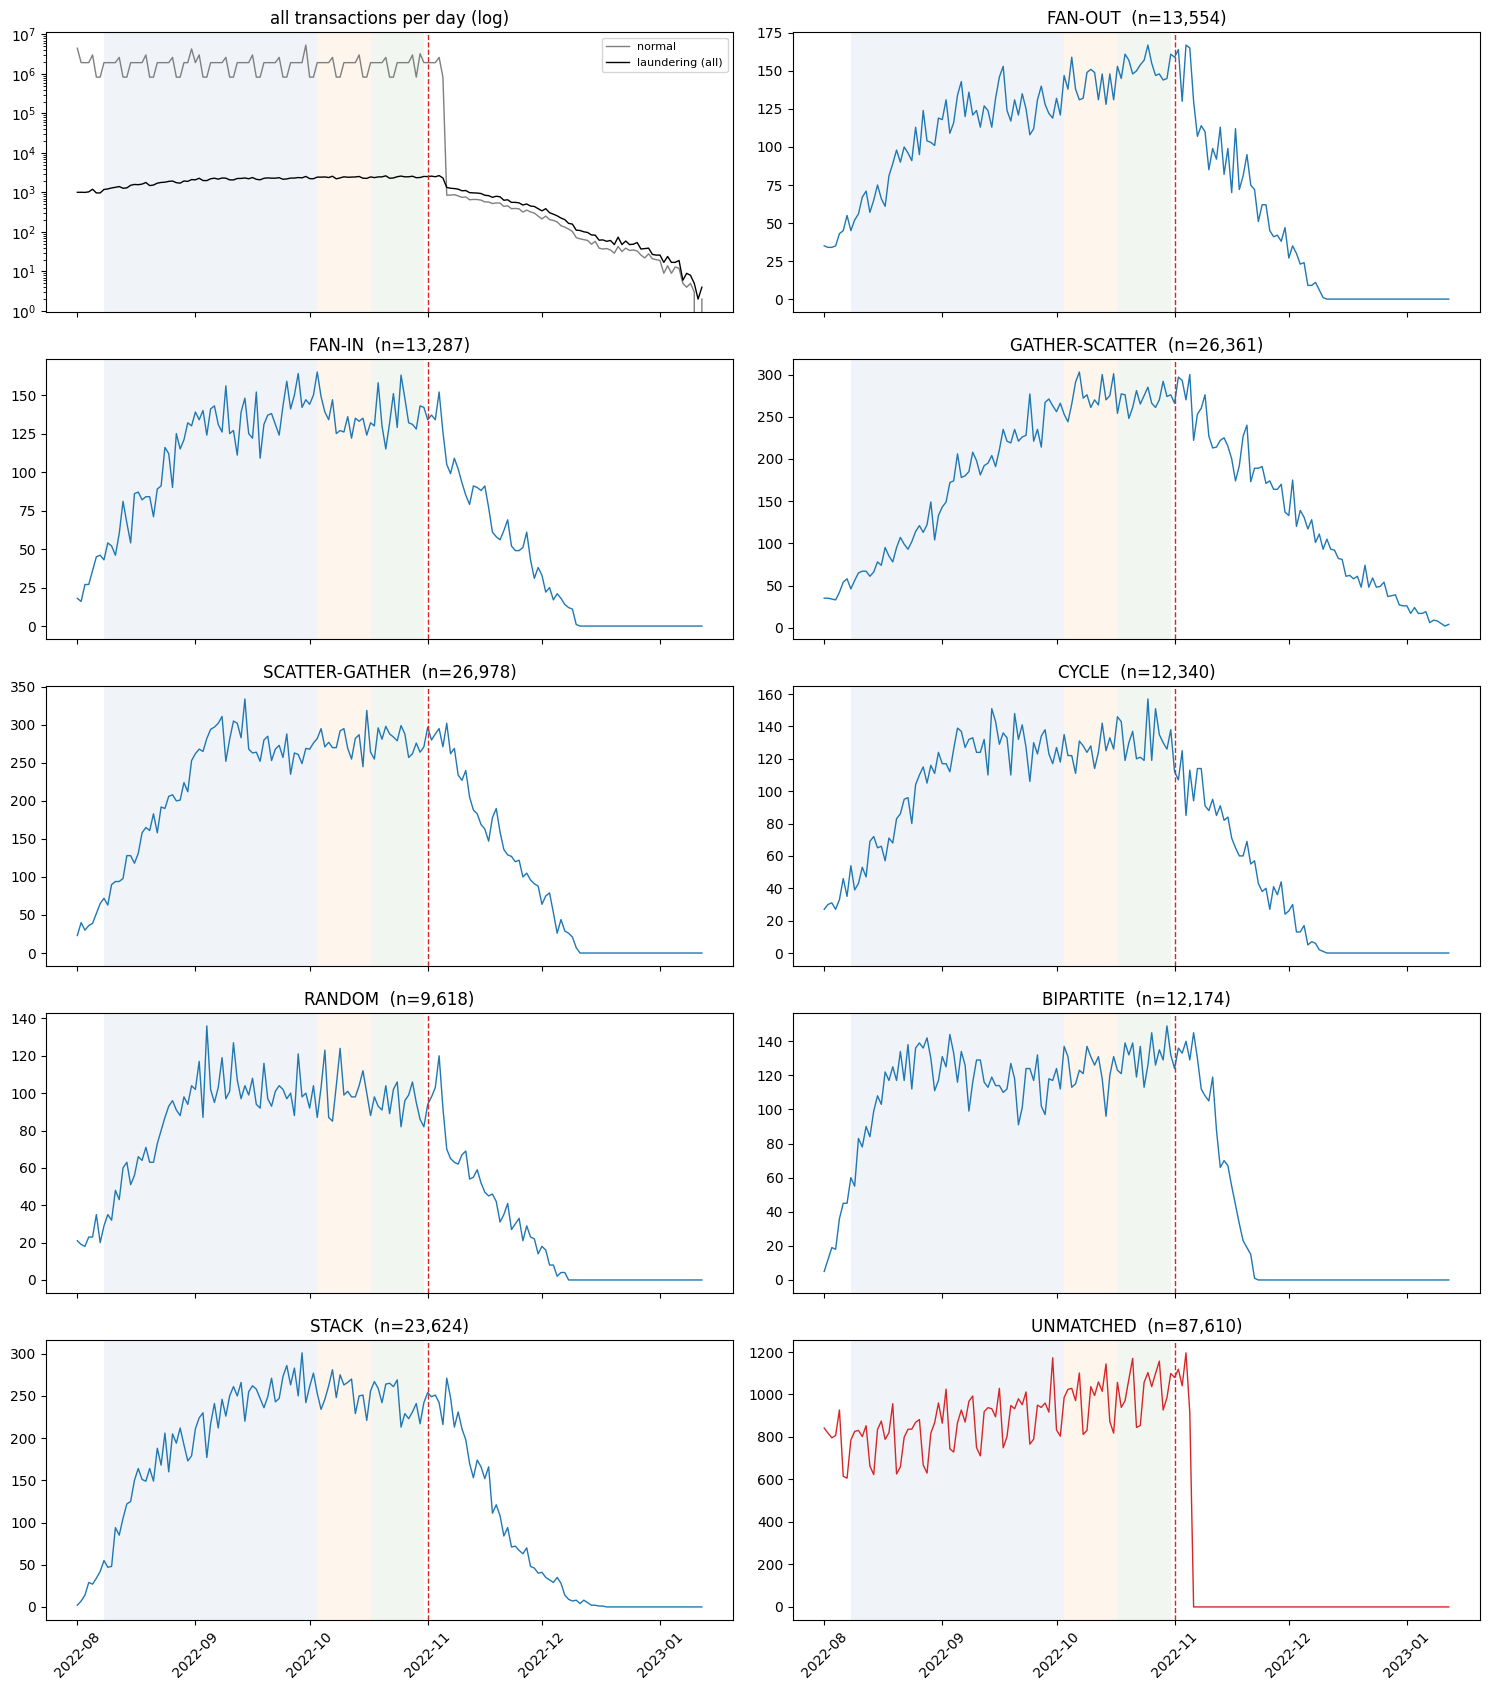

In [15]:
fig = M.plot_daily_classes(lau, windows, DATA_END, daily, path=OUT / "daily_classes.png")

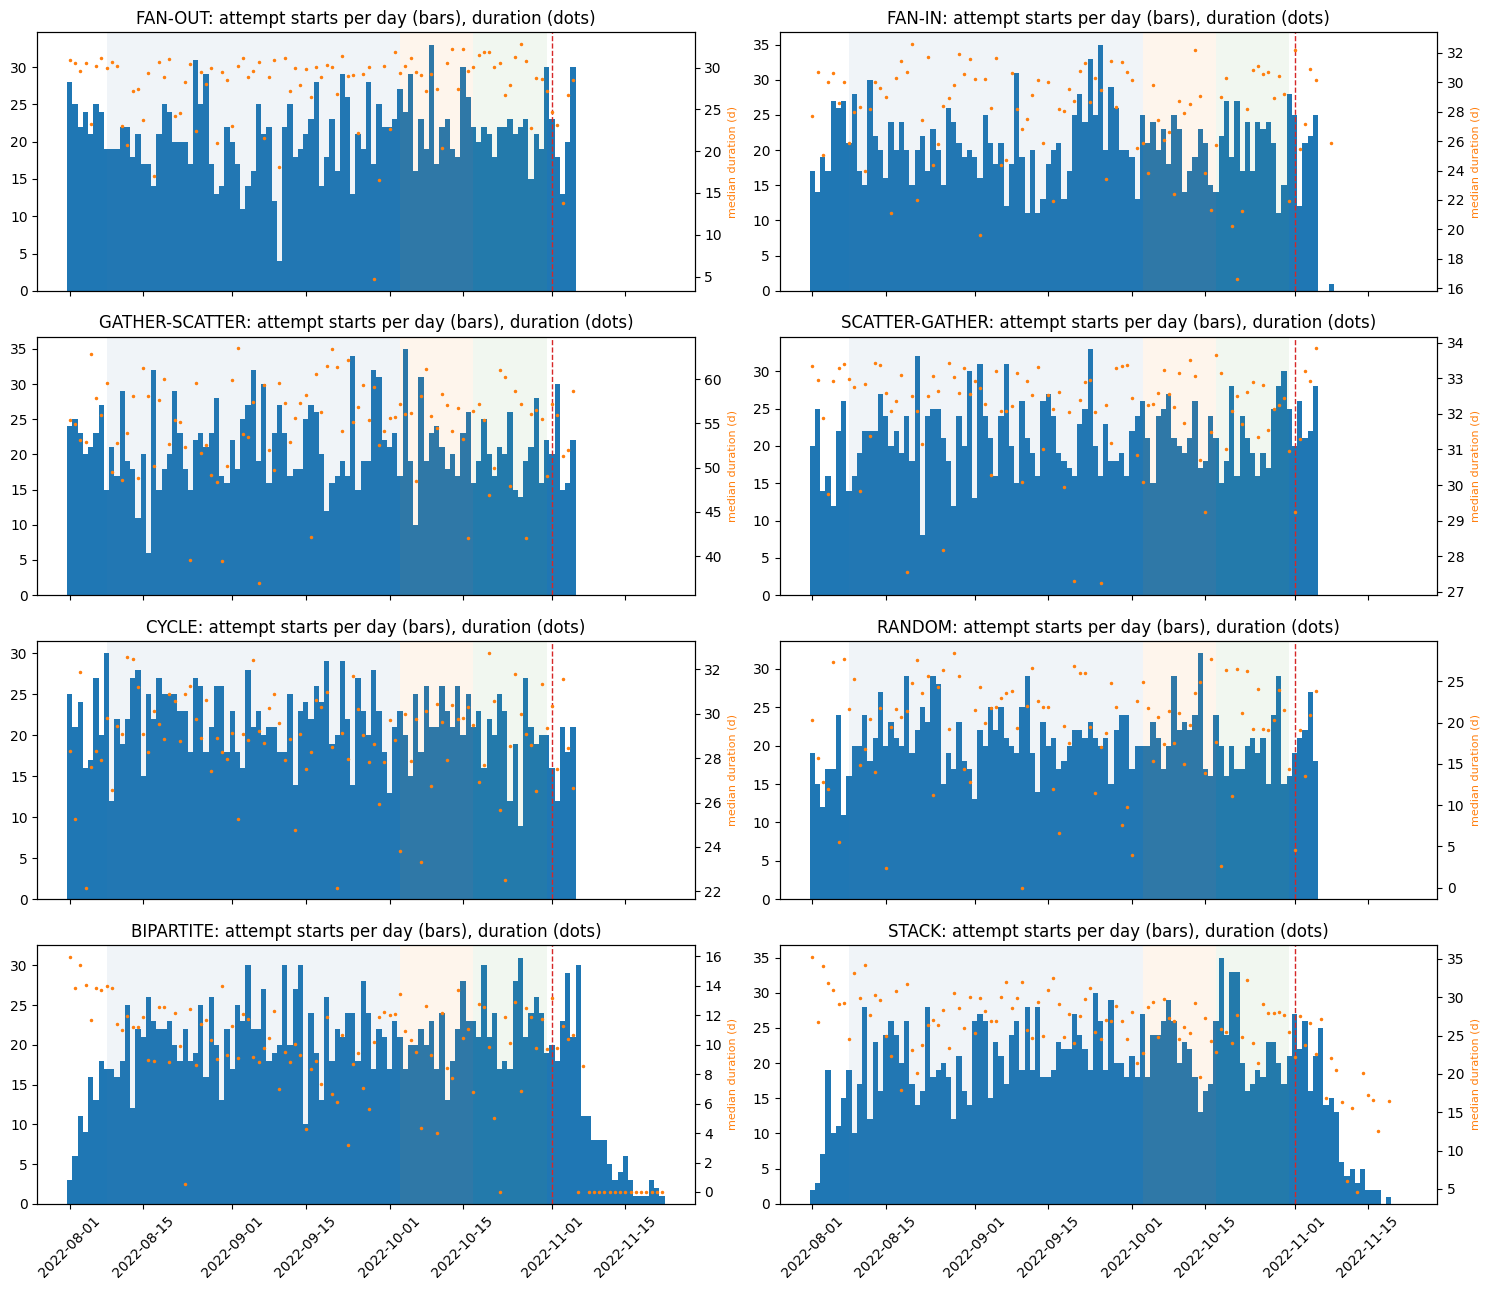

In [16]:
fig = M.plot_attempt_starts(att, windows, DATA_END, path=OUT / "attempt_starts.png")

## 5. 분할 후보 비교

변수만 바꿔 여러 분할을 한 표로 본다. `min_<split>` = 그 구간에서 가장 적은 클래스의 엣지 수, `test_with_earlier%` = 누수 후보 비율

`test_in_train%` = 테스트 패턴 엣지 중 같은 시도가 학습에도 있는 비율(라벨 누수 후보), `test_new%` = 테스트에서 시작한 시도의 엣지 비율

In [17]:
configs = {
    "binary_same":   (TRAIN, VAL, TEST),
    # 예시 — 필요하면 바꿔서 추가
    "longer_test":   (("2022-08-08", "2022-09-25"), ("2022-09-26", "2022-10-09"), ("2022-10-10", "2022-10-30")),
}
cmp = M.compare_splits(configs, lau, members, att, DATA_END)
cmp

,train,val,test,n_train,min_train,unmatched_train%,n_val,min_val,unmatched_val%,n_test,min_test,unmatched_test%,cut_%,test_with_earlier%,truncated_%
config,,,,,,,,,,,,,,,
binary_same,2022-08-08~2022-10-02,2022-10-03~2022-10-16,2022-10-17~2022-10-30,110671,4948 (RANDOM),43.2,33795,1425 (RANDOM),40.5,34460,1335 (RANDOM),41.4,52.60,69.23,24.94
longer_test,2022-08-08~2022-09-25,2022-09-26~2022-10-09,2022-10-10~2022-10-30,94309,4245 (RANDOM),43.7,33219,1416 (RANDOM),40.1,51398,2047 (RANDOM),41.3,56.71,60.23,24.94


,count,5%,25%,50%,75%,95%,max,IQR,mean
pattern_type,,,,,,,,,
FAN-OUT,2040.0,0.0,11.4,29.1,33.1,34.7,35.0,21.8,22.5
FAN-IN,2014.0,0.0,10.5,28.8,33.1,34.7,35.0,22.6,22.2
GATHER-SCATTER,2054.0,0.1,31.1,55.8,63.8,67.9,70.5,32.7,44.2
SCATTER-GATHER,2067.0,9.0,27.1,32.4,34.1,34.8,35.0,7.0,28.8
CYCLE,2086.0,5.5,20.6,29.2,32.7,34.6,35.0,12.1,25.6
RANDOM,2001.0,0.0,0.0,20.5,28.8,33.1,35.0,28.8,16.7
BIPARTITE,2109.0,0.0,0.0,10.4,14.3,16.0,16.9,14.3,8.2
STACK,2096.0,3.5,16.6,26.5,33.5,38.6,42.5,16.8,24.5


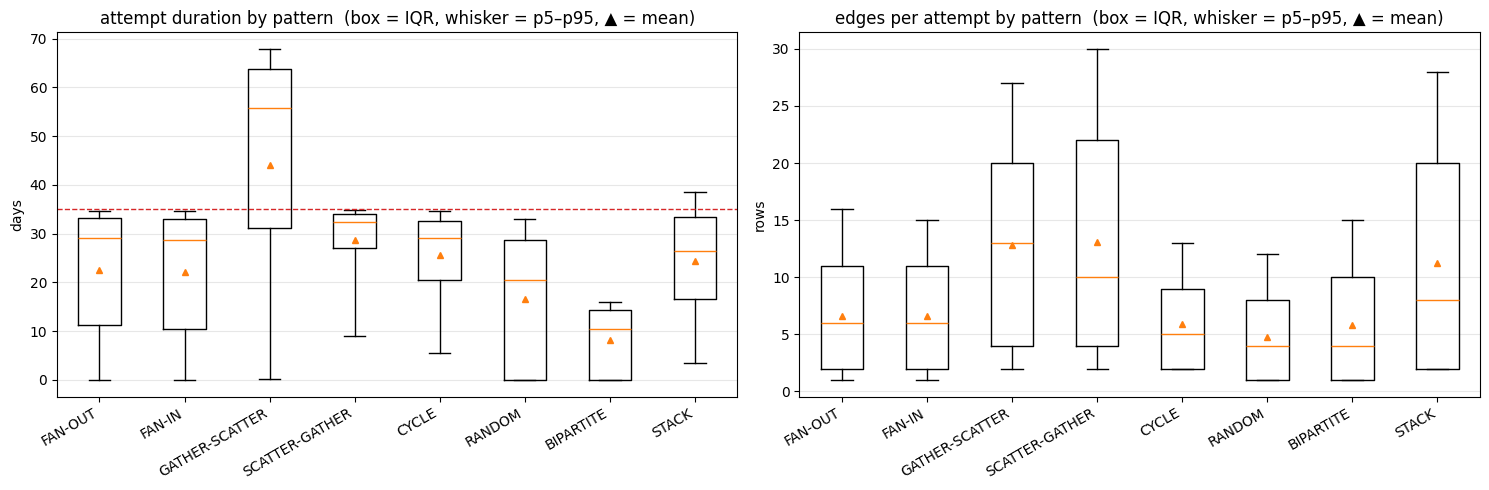

In [19]:
# 패턴별 시도 길이(일)·크기(행 수) 박스플롯 — 점선 = 35일 (다른 패턴의 최대 길이)
import matplotlib.pyplot as plt

d = att.assign(duration_d=att["duration_h"] / 24)
data_dur = [d.loc[d["pattern_type"] == p, "duration_d"].to_numpy() for p in M.PATTERNS]
data_rows = [d.loc[d["pattern_type"] == p, "n_rows"].to_numpy() for p in M.PATTERNS]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, data, title, ylabel in [(axes[0], data_dur, "attempt duration by pattern", "days"),
                                (axes[1], data_rows, "edges per attempt by pattern", "rows")]:
    ax.boxplot(data, whis=(5, 95), showfliers=False, showmeans=True,
               meanprops=dict(marker="^", markerfacecolor="#FF7F0E", markeredgecolor="#FF7F0E", markersize=5))
    ax.set_xticks(range(1, len(M.PATTERNS) + 1), M.PATTERNS, rotation=30, ha="right")
    ax.set_title(f"{title}  (box = IQR, whisker = p5–p95, ▲ = mean)")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.3)
axes[0].axhline(35, color="#D62728", lw=1, ls="--")
fig.tight_layout()
fig.savefig(OUT / "duration_box.png", dpi=110)

# 같은 내용 표 (IQR 포함)
q = d.groupby("pattern_type", observed=False)["duration_d"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95])
q["IQR"] = q["75%"] - q["25%"]
q[["count", "5%", "25%", "50%", "75%", "95%", "max", "IQR", "mean"]].round(1)

## 6. 시도 안의 순서 · 진행 중 모습

**6-1. 받기 → 보내기 순서** (GATHER-SCATTER 가 모으기 단계 → 뿌리기 단계로 생성됐는지)
- 중간 계좌 = 시도 안에서 받기도 하고 보내기도 한 계좌. `node_ordered_%` = 그중 마지막 입금 ≤ 첫 출금 인 비율
- `attempt_all_ordered_%` = 중간 계좌가 전부 ordered 인 시도 비율 (CYCLE 은 출발 계좌가 먼저 보내고 나중에 받으므로 원래 낮아야 정상)
- `has_inter_%` : 중간 계좌가 있는 시도 비율 — FAN-IN/FAN-OUT/BIPARTITE 는 0 에 가까워야 정상
- `hub_*` : hub(시도 안 in+out 최대 계좌)가 중간 계좌인 시도에서, 받기 구간 길이·보내기 구간 길이·사이 간격(음수 = 겹침) 중앙값(일),
  `hub_in_share_med` = hub 첫 출금 전까지 도착한 시도 엣지 비율 (G-S 의 모으기 단계 비중)

In [ ]:
po = M.phase_order(lau)
po["by_pattern"]

['attempt_starts.png',
 'attempts_start.csv',
 'attempts_touch.csv',
 'boundary_cuts.csv',
 'compare_splits.csv',
 'daily_classes.png',
 'duration.csv',
 'edge_exposure.csv',
 'edges.csv',
 'edges_share.csv',
 'last_seen.csv',
 'truncation.csv',
 'truncation_edges.csv',
 'truncation_normal_end.csv']

In [ ]:
fig = M.plot_hub_phases(po["hub"], path=OUT / "hub_phases.png")

**6-2. 진행 중 모습 (flat)** — 어떤 시점까지 보이는 시도 엣지만으로는 중간 계좌가 아직 없는 경우.
flat 인 GATHER-SCATTER 는 FAN-IN, SCATTER-GATHER 는 FAN-OUT, STACK 은 BIPARTITE 와 구조가 같다 (`looks_like`) → 구조만으로는 구분 불가능한 엣지 비율
- `causal_flat_%` : 엣지 자기 시각까지 보일 때 (실시간에 가장 불리한 경우)
- `at_end_flat_%` : 엣지가 속한 분할 끝까지 보일 때 (지금 실험의 그래프 조건)
- `never_inter_%` : 끝까지 중간 계좌가 안 생기는 시도 비율 (그 패턴은 원래 flat)

In [ ]:
fv = M.flat_view(lau, windows)
fv["by_split"].unstack(0)[["causal_flat_%", "at_end_flat_%"]]

In [ ]:
fv["never"]

## 7. 저장

In [18]:
for name, df in {"edges": sc["edges"], "edges_share": sc["edges_share"], "attempts_start": sc["attempts_start"],
                 "attempts_touch": sc["attempts_touch"], "boundary_cuts": bc["by_pattern"],
                 "edge_exposure": bc["edge_exposure"], "truncation": tr["attempts"], "truncation_edges": tr["edges"],
                 "truncation_normal_end": tr_n["attempts"], "last_seen": tr["last_seen"],
                 "duration": M.duration_table(att), "compare_splits": cmp,
                 "label_overlap": lo["edges"], "label_overlap_attempts": lo["attempts"],
                 "edge_age": age["quantiles"], "edge_age_bins": age["bins"],
                 "phase_order": po["by_pattern"], "flat_view": fv["by_split"], "flat_never": fv["never"]}.items():
    df.to_csv(OUT / f"{name}.csv", encoding="utf-8-sig")
sorted(p.name for p in OUT.iterdir())

['attempt_starts.png',
 'attempts_start.csv',
 'attempts_touch.csv',
 'boundary_cuts.csv',
 'compare_splits.csv',
 'daily_classes.png',
 'duration.csv',
 'edge_exposure.csv',
 'edges.csv',
 'edges_share.csv',
 'last_seen.csv',
 'truncation.csv',
 'truncation_edges.csv',
 'truncation_normal_end.csv']